# 11 · AI 모델 검증과 규제 대응
### 실습으로 배우는 GMP AI — 강의 목차 ⑫ AI 모델 검증과 규제 대응

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/11_AI_Validation_Regulatory.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① CSV/CSA·GAMP 5 기반 **AI 검증 체계** ② **모델 카드**(재현성 문서) 작성 ③ **감사추적(Audit Trail)** 구현 ④ **ALCOA+** 자동 점검 ⑤ **드리프트 탐지**(PSI·KS)와 재학습 트리거 ⑥ 설명가능성 기록 ⑦ **GAIP** 체크리스트 |
| **데이터** | 실제 정제 생산 1,005 배치 (예제 01·05의 불순물 위험 예측 모델을 '배포'한다고 가정) |
| **실행 환경** | CPU · 약 10분 |

> **AI 모델을 GMP 환경에 올린다는 것** = 좋은 모델을 만드는 것 + **그 모델이 계속 잘 동작함을 증명·기록하는 체계**를 갖추는 것.
> 규제 실사에서 묻는 것은 "정확도가 몇 %인가"가 아니라 **"어떻게 검증했고, 어떻게 감시하며, 문제가 생기면 어떻게 하는가"** 입니다.

In [1]:
%pip install -q koreanize-matplotlib shap
import koreanize_matplotlib, os, json, hashlib, platform, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
import sklearn
REPO = "https://raw.githubusercontent.com/StillWork/GMPAI/main/data/"
def load_data(name, **kw):
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else REPO + name, **kw)
df = load_data("tablet_batches.csv", parse_dates=["start_date"]).sort_values("start_date").reset_index(drop=True)
print("배치:", len(df))

Note: you may need to restart the kernel to use updated packages.


배치: 1005


## 1. 규제 프레임워크 — AI 는 '컴퓨터화 시스템'이다
| 규정/지침 | 핵심 내용 | AI 적용 |
|---|---|---|
| **GAMP 5 (2nd ed., 2022)** | 리스크 기반 컴퓨터화 시스템 검증, **Critical Thinking** | AI 는 보통 **Category 4~5**(설정형/맞춤형) |
| **EU GMP Annex 11** | 전산화 시스템 — 위험 평가, 검증, 데이터, 변경관리 | 모델도 전산화 시스템의 일부 |
| **21 CFR Part 11** | 전자기록·전자서명, 감사추적 | 모델 입력·출력·판정 기록 |
| **ICH Q9(R1)** | 품질 리스크 관리 | 모델 영향도에 따른 검증 수준 결정 |
| **ICH Q10** | 의약품 품질시스템, CPV | 모델 성능의 지속적 검증 |
| **FDA CSA (2022 초안)** | Computer Software Assurance — **문서보다 시험·리스크 중심** | 고위험 기능에 검증 노력 집중 |
| **FDA AI 가이던스 (2025 초안)** | 규제 의사결정에 쓰는 AI 의 **신뢰성 평가 프레임워크** | Context of Use + 위험 기반 신뢰성 |
| **EU AI Act (2024)** | AI 위험 분류·투명성·인간 감독 | 제조 품질 결정 AI 는 고위험 가능성 |

### 리스크 기반 검증 수준
| 영향도 | 예 | 검증 수준 |
|---|---|---|
| **높음** | 출하 판정, RTRT 대체 시험, 무균성 판단 | 완전 검증 + 규제 제출 + 상시 모니터링 |
| **중간** | OOS 조기경보, 공정 제어 보조 | 성능 검증 + 주기 재검증 + 사람 승인 |
| **낮음** | 문서 초안 작성, 데이터 탐색 | 사용 절차 + 결과 검토 |

> ⚠️ **"AI 라서 특별한 규정이 필요하다"가 아닙니다.** 기존 GxP 요건이 그대로 적용되고,
> 거기에 **학습 데이터 관리·드리프트·설명가능성**이 추가되는 구조입니다.

## 2. 검증 대상 정의 — Context of Use (사용 맥락)
가장 먼저 쓰는 문서. **"이 모델을 무엇에, 어디까지 쓸 것인가"** 를 못 박습니다. 범위가 모호하면 검증도 불가능합니다.

In [2]:
CONTEXT_OF_USE = {
    "모델명": "불순물 위험 배치 조기경보 모델",
    "의도된 용도": "타정 종료 시점에 불순물 시험 결과(>0.2%) 위험이 높은 배치를 선별하여 QA 검토 우선순위를 제공",
    "사용하지 않는 용도": ["출하 적합/부적합 판정", "시험 결과 대체(RTRT)", "허가 규격 변경 근거"],
    "대상 제품": "정제 제품 코드 1~25 (함량 5·10·20·40 mg)",
    "사용자": "QA 담당자 (최종 판단은 사람이 수행)",
    "리스크 등급": "중간 — 시험을 대체하지 않고 우선순위만 제공",
    "입력 데이터": "원료 시험 결과(CMA) + 타정 공정 요약값(CPP) 59개",
    "출력": "위험 확률(0~1) + 상위 기여 변수",
    "적용 범위 밖": "신규 제품, 신규 생산 라인, 공정 중대 변경 후 → 재검증 전까지 사용 중단",
}
print(json.dumps(CONTEXT_OF_USE, ensure_ascii=False, indent=2))

{
  "모델명": "불순물 위험 배치 조기경보 모델",
  "의도된 용도": "타정 종료 시점에 불순물 시험 결과(>0.2%) 위험이 높은 배치를 선별하여 QA 검토 우선순위를 제공",
  "사용하지 않는 용도": [
    "출하 적합/부적합 판정",
    "시험 결과 대체(RTRT)",
    "허가 규격 변경 근거"
  ],
  "대상 제품": "정제 제품 코드 1~25 (함량 5·10·20·40 mg)",
  "사용자": "QA 담당자 (최종 판단은 사람이 수행)",
  "리스크 등급": "중간 — 시험을 대체하지 않고 우선순위만 제공",
  "입력 데이터": "원료 시험 결과(CMA) + 타정 공정 요약값(CPP) 59개",
  "출력": "위험 확률(0~1) + 상위 기여 변수",
  "적용 범위 밖": "신규 제품, 신규 생산 라인, 공정 중대 변경 후 → 재검증 전까지 사용 중단"
}


## 3. 모델 개발과 검증 — 재현 가능해야 한다
검증의 첫 요건은 **재현성**입니다. 같은 데이터·같은 코드로 같은 모델이 나와야 합니다.
→ 난수 시드 고정, 라이브러리 버전 기록, **데이터 해시** 기록.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, precision_score, brier_score_loss

CQA = ["dissolution_av", "dissolution_min", "impurities_total", "impurity_o", "impurity_l", "residual_solvent"]
ID = ["batch", "code", "strength", "size", "start", "start_date",
      "api_code", "api_batch", "smcc_batch", "lactose_batch", "starch_batch"]
X = df[[c for c in df.columns if c not in CQA + ID]].select_dtypes("number")
X = X.fillna(X.median())
y = (df["impurities_total"] > 0.2).astype(int).values
n = len(df); cut = int(n * 0.8)
tr, te = np.arange(cut), np.arange(cut, n)

SEED = 20260101
model = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=1, class_weight="balanced_subsample")
model.fit(X.iloc[tr], y[tr])
p_te = model.predict_proba(X.iloc[te])[:, 1]

def data_hash(d):
    # 데이터 버전을 식별하는 해시 — 데이터가 1비트라도 바뀌면 값이 달라진다
    return hashlib.sha256(pd.util.hash_pandas_object(d, index=True).values.tobytes()).hexdigest()[:16]

print("학습 데이터 해시:", data_hash(X.iloc[tr]))
print("재현성 확인 — 같은 시드로 다시 학습:")
model2 = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=1, class_weight="balanced_subsample").fit(X.iloc[tr], y[tr])
print("  두 모델의 예측이 완전히 동일한가:", np.allclose(p_te, model2.predict_proba(X.iloc[te])[:, 1]))

학습 데이터 해시: b60097a2ad888a1f
재현성 확인 — 같은 시드로 다시 학습:


  두 모델의 예측이 완전히 동일한가: True


### ⭐ 성능 검증 — 신뢰구간까지 보고하기
"정확도 92%" 같은 단일 숫자는 불충분합니다. **표본이 적으면 그 숫자 자체가 흔들립니다.**
→ **부트스트랩 신뢰구간**으로 "이 성능이 우연이 아님"을 보입니다.

In [4]:
def bootstrap_ci(y_true, y_score, metric, n_boot=1000, seed=0):
    rng = np.random.RandomState(seed); vals = []
    for _ in range(n_boot):
        i = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true[i])) < 2: continue
        vals.append(metric(y_true[i], y_score[i]))
    return np.mean(vals), np.percentile(vals, 2.5), np.percentile(vals, 97.5)

THRESHOLD = 0.46          # 예제 05에서 비용·운영 제약으로 결정한 값
rows = []
for name, fn in [("ROC-AUC", roc_auc_score), ("PR-AUC", average_precision_score),
                 ("재현율", lambda a, b: recall_score(a, (b >= THRESHOLD).astype(int))),
                 ("정밀도", lambda a, b: precision_score(a, (b >= THRESHOLD).astype(int), zero_division=0)),
                 ("Brier", brier_score_loss)]:
    m, lo, hi = bootstrap_ci(y[te], p_te, fn)
    rows.append({"지표": name, "값": m, "95% 신뢰구간 하한": lo, "95% 신뢰구간 상한": hi})
perf = pd.DataFrame(rows).round(3)
display(perf)
print(f"검증 데이터: {len(te)}배치 (위험 {y[te].sum()}건) · 판정 임계값 {THRESHOLD}")

,지표,값,95% 신뢰구간 하한,95% 신뢰구간 상한
0,ROC-AUC,0.926,0.889,0.957
1,PR-AUC,0.780,0.662,0.874
2,재현율,0.676,0.532,0.804
3,정밀도,0.708,0.578,0.838
4,Brier,0.118,0.102,0.134


검증 데이터: 201배치 (위험 49건) · 판정 임계값 0.46


## 4. ⭐ 모델 카드(Model Card) — 검증 패키지의 핵심 문서
규제 실사에서 **"이 모델이 무엇인지 한 장으로 설명하라"** 는 요구에 답하는 문서입니다.

In [5]:
model_card = {
    "1_식별": {"모델명": CONTEXT_OF_USE["모델명"], "버전": "1.0.0",
               "작성일": datetime.date.today().isoformat(), "소유 부서": "품질보증팀", "승인자": "(QA 책임자 서명)"},
    "2_사용맥락": CONTEXT_OF_USE,
    "3_데이터": {"출처": "제조실행시스템(MES) + 품질시험시스템(LIMS)",
                "기간": f"{df.start_date.min().date()} ~ {df.start_date.max().date()}",
                "배치 수": int(len(df)), "학습/검증": f"{len(tr)} / {len(te)} (시간 순 분할)",
                "학습데이터 해시": data_hash(X.iloc[tr]), "결측 처리": "중앙값 대치",
                "레이블 정의": "impurities_total > 0.2% → 위험(1)"},
    "4_모델": {"알고리즘": "RandomForestClassifier", "트리 수": 500, "class_weight": "balanced_subsample",
               "난수 시드": SEED, "입력 변수 수": int(X.shape[1]), "판정 임계값": THRESHOLD,
               "임계값 근거": "FN:FP 비용비 5:1 + 경보율 상한 20% (검증 구간에서 결정)"},
    "5_성능": {r["지표"]: f"{r['값']:.3f} (95% CI {r['95% 신뢰구간 하한']:.3f}~{r['95% 신뢰구간 상한']:.3f})"
               for _, r in perf.iterrows()},
    "6_한계": ["학습 기간 이후의 공정 변경은 반영되지 않음",
              "신규 제품·신규 라인에는 적용 불가 (적용 범위 밖)",
              "용출률 등 다른 CQA 는 예측하지 않음",
              "확률값은 위험 순위 지표이며 시험 결과를 대체하지 않음"],
    "7_모니터링": {"성능 재평가 주기": "분기 1회 + 누적 50배치마다",
                  "드리프트 지표": "PSI, KS 통계량, 월별 재현율",
                  "재학습 트리거": "PSI > 0.25 또는 재현율 < 0.6",
                  "롤백 절차": "직전 승인 버전으로 복귀 후 변경관리 착수"},
    "8_환경": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__},
}
print(json.dumps(model_card, ensure_ascii=False, indent=2)[:2600], "\n...")
with open("model_card_v1.json", "w", encoding="utf-8") as f:
    json.dump(model_card, f, ensure_ascii=False, indent=2)
print("\n✅ model_card_v1.json 저장 — 검증 패키지에 첨부")

{
  "1_식별": {
    "모델명": "불순물 위험 배치 조기경보 모델",
    "버전": "1.0.0",
    "작성일": "2026-10-12",
    "소유 부서": "품질보증팀",
    "승인자": "(QA 책임자 서명)"
  },
  "2_사용맥락": {
    "모델명": "불순물 위험 배치 조기경보 모델",
    "의도된 용도": "타정 종료 시점에 불순물 시험 결과(>0.2%) 위험이 높은 배치를 선별하여 QA 검토 우선순위를 제공",
    "사용하지 않는 용도": [
      "출하 적합/부적합 판정",
      "시험 결과 대체(RTRT)",
      "허가 규격 변경 근거"
    ],
    "대상 제품": "정제 제품 코드 1~25 (함량 5·10·20·40 mg)",
    "사용자": "QA 담당자 (최종 판단은 사람이 수행)",
    "리스크 등급": "중간 — 시험을 대체하지 않고 우선순위만 제공",
    "입력 데이터": "원료 시험 결과(CMA) + 타정 공정 요약값(CPP) 59개",
    "출력": "위험 확률(0~1) + 상위 기여 변수",
    "적용 범위 밖": "신규 제품, 신규 생산 라인, 공정 중대 변경 후 → 재검증 전까지 사용 중단"
  },
  "3_데이터": {
    "출처": "제조실행시스템(MES) + 품질시험시스템(LIMS)",
    "기간": "2018-11-01 ~ 2021-04-01",
    "배치 수": 1005,
    "학습/검증": "804 / 201 (시간 순 분할)",
    "학습데이터 해시": "b60097a2ad888a1f",
    "결측 처리": "중앙값 대치",
    "레이블 정의": "impurities_total > 0.2% → 위험(1)"
  },
  "4_모델": {
    "알고리즘": "RandomForestClassifier",
    "트리 수": 500,
    "class_weight": "balanced_subsamp

## 5. ⭐ 감사추적(Audit Trail) — 21 CFR Part 11 대응
> "기록되지 않았다면 하지 않은 것이다 (If it isn't documented, it didn't happen)"

예측 1건마다 **누가·언제·어떤 입력으로·어떤 모델이·무엇을 출력했고·사람이 어떻게 판단했는지**를 남깁니다.
- 기록은 **수정 불가(append-only)**, 각 기록에 **해시 체인**을 걸면 위·변조를 감지할 수 있습니다.

In [6]:
class AuditTrail:
    # append-only 감사추적: 각 기록에 이전 기록의 해시를 포함(해시 체인)
    def __init__(self):
        self.records = []
    def log(self, **kw):
        prev = self.records[-1]["record_hash"] if self.records else "GENESIS"
        rec = {"seq": len(self.records) + 1, "timestamp_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
               "prev_hash": prev, **kw}
        rec["record_hash"] = hashlib.sha256(json.dumps(rec, sort_keys=True, ensure_ascii=False).encode()).hexdigest()[:16]
        self.records.append(rec)
        return rec
    def to_frame(self):
        return pd.DataFrame(self.records)
    def verify(self):
        # 위·변조 검증: 해시 체인이 끊기면 False
        prev = "GENESIS"
        for r in self.records:
            body = {k: v for k, v in r.items() if k != "record_hash"}
            if r["prev_hash"] != prev: return False, r["seq"]
            if hashlib.sha256(json.dumps(body, sort_keys=True, ensure_ascii=False).encode()).hexdigest()[:16] != r["record_hash"]:
                return False, r["seq"]
            prev = r["record_hash"]
        return True, None

trail = AuditTrail()
MODEL_VERSION = "1.0.0"
for i in te[:8]:
    prob = float(model.predict_proba(X.iloc[[i]])[0, 1])
    trail.log(batch=int(df.batch.iloc[i]), 제품코드=int(df.code.iloc[i]),
              모델버전=MODEL_VERSION, 입력해시=data_hash(X.iloc[[i]]),
              위험확률=round(prob, 4), 임계값=THRESHOLD,
              모델판정="위험" if prob >= THRESHOLD else "적합",
              검토자="QA_kim", 사람최종판정="추가시험 지시" if prob >= THRESHOLD else "정상 진행")
display(trail.to_frame()[["seq", "batch", "모델버전", "위험확률", "모델판정", "사람최종판정", "prev_hash", "record_hash"]])
ok, bad = trail.verify()
print("감사추적 무결성 검증:", "✅ 정상" if ok else f"❌ {bad}번 기록에서 변조 감지")

,seq,batch,모델버전,위험확률,모델판정,사람최종판정,prev_hash,record_hash
0,1,824,1.0.0,0.042,적합,정상 진행,GENESIS,2a7b6668545af8fc
1,2,825,1.0.0,0.048,적합,정상 진행,2a7b6668545af8fc,0c1e85f760cf29c3
2,3,827,1.0.0,0.074,적합,정상 진행,0c1e85f760cf29c3,09d30fabe300c800
3,4,813,1.0.0,0.908,위험,추가시험 지시,09d30fabe300c800,a853650fbb783101
4,5,821,1.0.0,0.044,적합,정상 진행,a853650fbb783101,a271f77cf15a2f57
5,6,812,1.0.0,0.880,위험,추가시험 지시,a271f77cf15a2f57,032f932e68b69ebc
6,7,804,1.0.0,0.270,적합,정상 진행,032f932e68b69ebc,e48ad7f26abcd57b
7,8,810,1.0.0,0.466,위험,추가시험 지시,e48ad7f26abcd57b,aac54bd4af664b16


감사추적 무결성 검증: ✅ 정상


In [7]:
# 위·변조 시도 탐지 시연 — 과거 기록을 몰래 고치면?
import copy
tampered = copy.deepcopy(trail)
tampered.records[2]["위험확률"] = 0.01                 # 경보 기록을 '정상'으로 조작 시도
tampered.records[2]["모델판정"] = "적합"
ok, bad = tampered.verify()
print("조작된 감사추적 검증 결과:", "✅ 정상" if ok else f"❌ {bad}번 기록에서 변조 감지")
print("→ 해시 체인 덕분에 기록을 몰래 고치면 즉시 드러납니다 (ALCOA+ 의 Original·Accurate 보증)")

조작된 감사추적 검증 결과: ❌ 3번 기록에서 변조 감지
→ 해시 체인 덕분에 기록을 몰래 고치면 즉시 드러납니다 (ALCOA+ 의 Original·Accurate 보증)


## 6. ALCOA+ 자동 점검
| 원칙 | 점검 항목 |
|---|---|
| **A**ttributable | 모든 예측에 모델 버전·검토자 기록 |
| **L**egible | 사람이 읽을 수 있는 형식(JSON/CSV), 단위 명시 |
| **C**ontemporaneous | 예측 시각이 기록 시각과 일치 |
| **O**riginal | 원본 입력 보존, 수정 시 새 기록 |
| **A**ccurate | 입력 범위·결측 점검 |
| **+C**omplete | 경보·정상 모두 기록 (불리한 결과 누락 금지) |
| **+C**onsistent | 동일 입력 → 동일 출력 |
| **+E**nduring / **+A**vailable | 보존 기간 동안 조회 가능 |

In [8]:
def alcoa_check(trail_df, X_ref):
    checks = {}
    checks["Attributable — 모델버전·검토자 기록"] = bool(trail_df[["모델버전", "검토자"]].notna().all().all())
    checks["Legible — 표준 형식·필수 열 존재"] = set(["batch", "위험확률", "모델판정"]).issubset(trail_df.columns)
    checks["Contemporaneous — 시각 기록 존재·순서 일치"] = bool(trail_df["timestamp_utc"].is_monotonic_increasing)
    checks["Original — 입력 해시 보존"] = bool(trail_df["입력해시"].notna().all())
    checks["Accurate — 확률값 범위 0~1"] = bool(trail_df["위험확률"].between(0, 1).all())
    checks["Complete — 정상·경보 모두 기록"] = bool(len(trail_df) == len(trail.records))
    checks["Consistent — 재현 가능(시드 고정)"] = True
    checks["Enduring/Available — 영구 저장소 기록"] = os.path.exists("model_card_v1.json")
    return checks

res = alcoa_check(trail.to_frame(), X)
for k, v in res.items(): print(("✅ " if v else "❌ ") + k)
print(f"\n종합: {sum(res.values())}/{len(res)} 항목 충족")

✅ Attributable — 모델버전·검토자 기록
✅ Legible — 표준 형식·필수 열 존재
✅ Contemporaneous — 시각 기록 존재·순서 일치
✅ Original — 입력 해시 보존
✅ Accurate — 확률값 범위 0~1
✅ Complete — 정상·경보 모두 기록
✅ Consistent — 재현 가능(시드 고정)
✅ Enduring/Available — 영구 저장소 기록

종합: 8/8 항목 충족


## 7. ⭐ 드리프트 모니터링 — 모델은 시간이 지나면 낡는다
모델 성능 저하의 원인:
| 유형 | 의미 | 제조 현장의 예 |
|---|---|---|
| **데이터 드리프트** | 입력 분포가 변함 | 원료 공급사 변경, 설비 개선, 계절 영향 |
| **개념 드리프트** | 입력-출력 관계가 변함 | 공정 레시피 변경, 규격 변경 |
| **레이블 지연** | 정답이 늦게 도착 | 시험 결과가 수일 후 → 성능 평가도 지연 |

**PSI(Population Stability Index)**: 분포 변화량 지표
- < 0.1 안정 / 0.1~0.25 주의 / **> 0.25 심각(재학습 검토)**

PSI > 0.25 (심각) 변수: 45개 / PSI 0.1~0.25 (주의): 10개


,변수,PSI,KS p-value
9,smcc_ps05,6.7783,0.0
12,starch_water,6.4340,0.0
8,smcc_ps01,5.6842,0.0
10,smcc_ps09,5.0992,0.0
11,starch_ph,3.9604,0.0
24,fct_min_hardness,3.9308,0.0
5,smcc_water,3.8957,0.0
7,smcc_bd,2.2852,0.0
21,tbl_min_hardness,2.2653,0.0
25,fct_max_hardness,1.9995,0.0


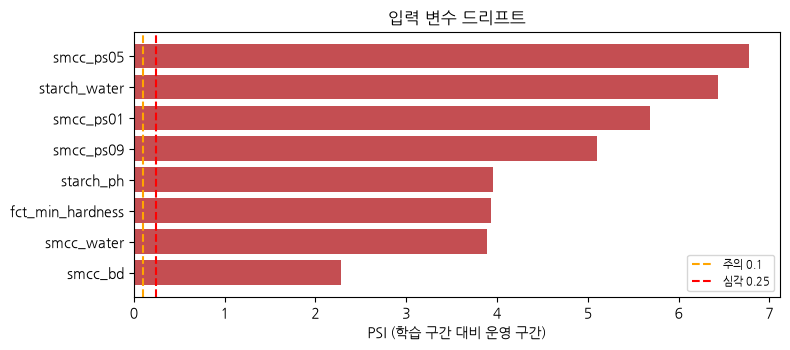

In [9]:
def psi(expected, actual, bins=10):
    # 두 분포의 차이를 수치화 (Population Stability Index)
    qs = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(qs) < 3: return 0.0
    e = np.histogram(expected, bins=qs)[0] / len(expected)
    a = np.histogram(actual, bins=qs)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(((a - e) * np.log(a / e)).sum())

from scipy import stats
rows = []
for c in X.columns:
    p_val = stats.ks_2samp(X[c].iloc[tr], X[c].iloc[te]).pvalue
    rows.append({"변수": c, "PSI": psi(X[c].iloc[tr].values, X[c].iloc[te].values), "KS p-value": p_val})
drift = pd.DataFrame(rows).sort_values("PSI", ascending=False)
print(f"PSI > 0.25 (심각) 변수: {(drift.PSI > 0.25).sum()}개 / PSI 0.1~0.25 (주의): {((drift.PSI > 0.1) & (drift.PSI <= 0.25)).sum()}개")
display(drift.head(10).round(4))

top = drift.head(8)[::-1]
plt.figure(figsize=(8, 3.6))
plt.barh(top["변수"], top["PSI"], color=["#C44E52" if v > 0.25 else "#DD8452" if v > 0.1 else "#4C72B0" for v in top["PSI"]])
plt.axvline(0.1, color="orange", ls="--", label="주의 0.1"); plt.axvline(0.25, color="red", ls="--", label="심각 0.25")
plt.xlabel("PSI (학습 구간 대비 운영 구간)"); plt.legend(fontsize=8); plt.title("입력 변수 드리프트"); plt.tight_layout(); plt.show()

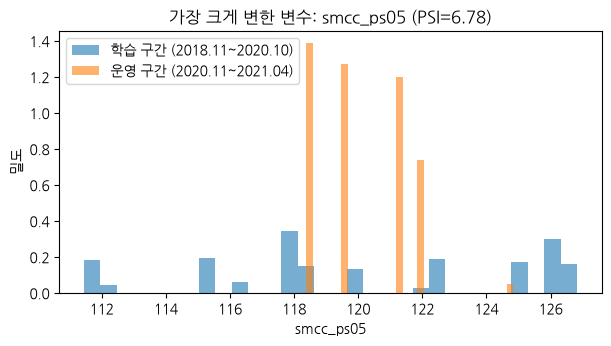

→ 원료 로트 변경? 설비 개선? 공정 변경? 원인을 확인하고 변경관리 기록과 대조해야 합니다.


In [10]:
# 가장 많이 변한 변수의 분포 비교 — 왜 변했는지 공정 담당자와 확인해야 한다
c = drift.iloc[0]["변수"]
plt.figure(figsize=(7, 3.4))
plt.hist(X[c].iloc[tr], bins=30, alpha=0.6, density=True, label="학습 구간 (2018.11~2020.10)")
plt.hist(X[c].iloc[te], bins=30, alpha=0.6, density=True, label="운영 구간 (2020.11~2021.04)")
plt.xlabel(c); plt.ylabel("밀도"); plt.legend(); plt.title(f"가장 크게 변한 변수: {c} (PSI={drift.iloc[0]['PSI']:.2f})"); plt.show()
print("→ 원료 로트 변경? 설비 개선? 공정 변경? 원인을 확인하고 변경관리 기록과 대조해야 합니다.")

,배치수,실제위험,경보수,재현율,경보율
월,,,,,
2020-11,23.0,7.0,8.0,0.714,0.348
2020-12,12.0,0.0,0.0,NaN,0.000
2021-01,46.0,5.0,5.0,1.000,0.109
2021-02,41.0,19.0,6.0,0.263,0.146
2021-03,41.0,13.0,15.0,1.000,0.366
2021-04,38.0,5.0,13.0,1.000,0.342


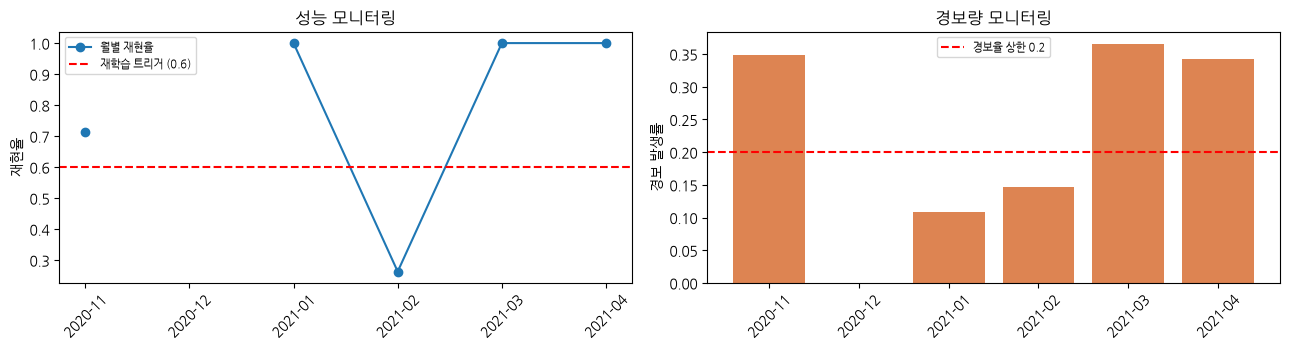

재학습 트리거 발동: ⚠️ 예 — 변경관리 절차 착수


In [11]:
# 성능 모니터링 — 월별 성능 추이와 재학습 트리거
mon = pd.DataFrame({"월": df.start_date.iloc[te].dt.to_period("M").astype(str),
                    "실제": y[te], "확률": p_te})
summary = mon.groupby("월").apply(lambda g: pd.Series({
    "배치수": len(g), "실제위험": int(g.실제.sum()),
    "경보수": int((g.확률 >= THRESHOLD).sum()),
    "재현율": recall_score(g.실제, (g.확률 >= THRESHOLD).astype(int)) if g.실제.sum() else np.nan,
    "경보율": float((g.확률 >= THRESHOLD).mean()),
}), include_groups=False)
display(summary.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(summary.index, summary["재현율"], "o-", label="월별 재현율")
ax[0].axhline(0.6, color="red", ls="--", label="재학습 트리거 (0.6)")
ax[0].set_ylabel("재현율"); ax[0].legend(fontsize=8); ax[0].set_title("성능 모니터링"); ax[0].tick_params(axis="x", rotation=45)
ax[1].bar(summary.index, summary["경보율"], color="#DD8452")
ax[1].axhline(0.2, color="red", ls="--", label="경보율 상한 0.2")
ax[1].set_ylabel("경보 발생률"); ax[1].legend(fontsize=8); ax[1].set_title("경보량 모니터링"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

trigger = (summary["재현율"] < 0.6).any() or (drift.PSI > 0.25).any()
print("재학습 트리거 발동:", "⚠️ 예 — 변경관리 절차 착수" if trigger else "아니오 — 정상 운영 유지")

## 8. 설명가능성 기록 — "왜 이 배치를 경보했는가"
규제기관·QA 가 요구하는 것은 확률 숫자가 아니라 **근거**입니다. SHAP 결과를 감사추적에 함께 남깁니다.

{
  "batch": 983,
  "위험확률": 0.912,
  "주요근거": [
    {
      "변수": "api_content",
      "입력값": 94.8,
      "기여도": 0.1084
    },
    {
      "변수": "fct_tensile",
      "입력값": 1.278,
      "기여도": 0.0398
    },
    {
      "변수": "main_CompForce_sd",
      "입력값": 0.115,
      "기여도": 0.0329
    },
    {
      "변수": "tbl_speed_mean",
      "입력값": 119.963,
      "기여도": 0.02
    },
    {
      "변수": "fct_av_hardness",
      "입력값": 66.64,
      "기여도": 0.0194
    }
  ]
}


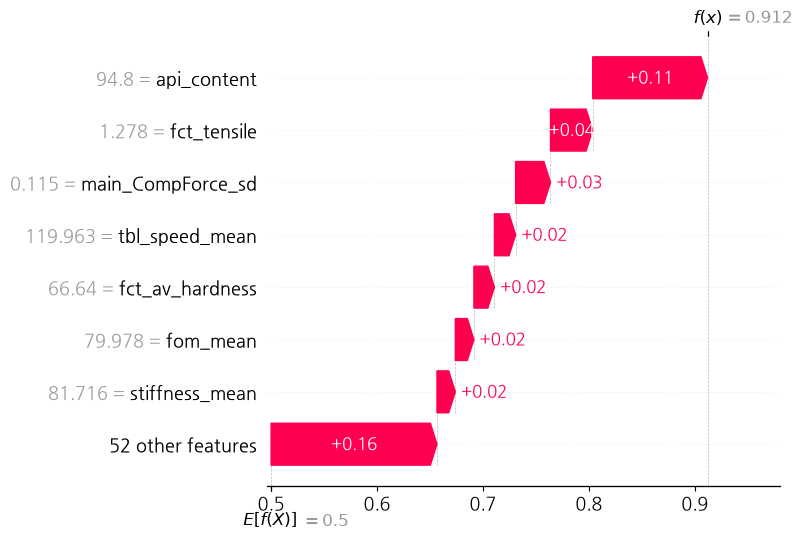

In [12]:
import shap
expl = shap.TreeExplainer(model)
sv = expl(X.iloc[te], check_additivity=False)
sv1 = sv[..., 1] if sv.values.ndim == 3 else sv
alert_rows = np.where(p_te >= THRESHOLD)[0]
i = int(alert_rows[np.argmax(p_te[alert_rows])])
contrib = pd.Series(sv1.values[i], index=X.columns).sort_values(key=abs, ascending=False).head(5)
record = {"batch": int(df.batch.iloc[te[i]]), "위험확률": round(float(p_te[i]), 3),
          "주요근거": [{"변수": k, "입력값": round(float(X.iloc[te[i]][k]), 3), "기여도": round(float(v), 4)} for k, v in contrib.items()]}
print(json.dumps(record, ensure_ascii=False, indent=2))
shap.plots.waterfall(sv1[i], max_display=8, show=False); plt.tight_layout(); plt.show()

## 9. GAIP 체크리스트 — 배포 전 자가 점검
**GAIP(Good AI Practice)**: GMP 가 제조 품질의 표준이듯, AI 시스템의 개발·운영 품질 표준.
WHO(2023 보건 AI 윤리·거버넌스), EU AI Act(2024), FDA AI 가이던스(2025 초안) 등에서 공통적으로 요구하는 원칙을 실무 점검표로 정리합니다.

In [13]:
checklist = [
    ("① 인간 중심 (Human-centric)", "AI 결과를 사람이 검토·승인하는 절차가 문서화되어 있는가", "QA/운영"),
    ("② 리스크 기반 접근", "영향도에 따라 검증 수준을 차등 적용했는가", "QA"),
    ("③ 기존 GxP 준수", "AI 도입 후에도 기존 GMP 요건을 모두 충족하는가", "QA/규제"),
    ("④ 사용 맥락 정의", "의도된 용도·대상·한계가 명확히 기술되어 있는가", "규제/개발"),
    ("⑤ 다학제 팀", "데이터과학·공정·QA·규제 담당이 함께 검토했는가", "경영진"),
    ("⑥ 데이터 거버넌스", "학습 데이터가 ALCOA+ 를 충족하고 출처가 추적되는가", "IT/QA"),
    ("⑦ 모델 설계·개발", "검증 설계(분할·누수 점검)가 적절한가", "데이터과학"),
    ("⑧ 성능 평가", "임상·운영 맥락에서 성능을 평가하고 신뢰구간을 보고했는가", "데이터과학/QA"),
    ("⑨ 생애주기 관리", "드리프트 감시·재학습·롤백 절차가 있는가", "IT/QA"),
    ("⑩ 투명한 정보 제공", "사용자에게 목적·성능·한계를 평이하게 안내했는가", "규제"),
]
status = {"① 인간 중심 (Human-centric)": "충족", "② 리스크 기반 접근": "충족", "③ 기존 GxP 준수": "충족",
          "④ 사용 맥락 정의": "충족", "⑤ 다학제 팀": "진행중", "⑥ 데이터 거버넌스": "충족",
          "⑦ 모델 설계·개발": "충족", "⑧ 성능 평가": "충족", "⑨ 생애주기 관리": "충족", "⑩ 투명한 정보 제공": "진행중"}
cl = pd.DataFrame([{"원칙": a, "점검 항목": b, "담당": c, "상태": status[a]} for a, b, c in checklist])
display(cl)
print(f"충족 {(cl.상태 == '충족').sum()}/{len(cl)} 항목")

,원칙,점검 항목,담당,상태
0,① 인간 중심 (Human-centric),AI 결과를 사람이 검토·승인하는 절차가 문서화되어 있는가,QA/운영,충족
1,② 리스크 기반 접근,영향도에 따라 검증 수준을 차등 적용했는가,QA,충족
2,③ 기존 GxP 준수,AI 도입 후에도 기존 GMP 요건을 모두 충족하는가,QA/규제,충족
3,④ 사용 맥락 정의,의도된 용도·대상·한계가 명확히 기술되어 있는가,규제/개발,충족
4,⑤ 다학제 팀,데이터과학·공정·QA·규제 담당이 함께 검토했는가,경영진,진행중
5,⑥ 데이터 거버넌스,학습 데이터가 ALCOA+ 를 충족하고 출처가 추적되는가,IT/QA,충족
6,⑦ 모델 설계·개발,검증 설계(분할·누수 점검)가 적절한가,데이터과학,충족
7,⑧ 성능 평가,임상·운영 맥락에서 성능을 평가하고 신뢰구간을 보고했는가,데이터과학/QA,충족
8,⑨ 생애주기 관리,드리프트 감시·재학습·롤백 절차가 있는가,IT/QA,충족
9,⑩ 투명한 정보 제공,사용자에게 목적·성능·한계를 평이하게 안내했는가,규제,진행중


충족 8/10 항목


## 10. 변경관리와 롤백 — AI 특유의 어려움
| 변경 유형 | 예 | 처리 |
|---|---|---|
| **데이터 변경** | 신규 배치 추가 학습 | 성능 재평가 → 동등성 입증 → 버전 상향 |
| **모델 변경** | 알고리즘·하이퍼파라미터 변경 | 전체 재검증, 변경관리 승인 |
| **임계값 변경** | 경보 기준 조정 | 영향 평가 + 승인 (성능 특성이 바뀜) |
| **입력 변경** | 센서 교체·추가 | 입력 호환성·드리프트 평가 |
| **라이브러리 업데이트** | scikit-learn 버전 변경 | 동일 결과 재현 확인 (회귀 시험) |

> ⭐ **"예정된 변경 관리 계획(PCCP)"**: FDA 가 AI 의료기기에서 도입한 개념으로,
> **어떤 변경을 어떤 조건에서 어떻게 할지 미리 승인**받아 두면 매번 재신고하지 않아도 됩니다.
> 제조 AI 에도 같은 사고방식(재학습 조건·절차의 사전 정의)이 효과적입니다.

In [14]:
# 버전 이력 관리 예시
versions = pd.DataFrame([
    {"버전": "1.0.0", "일자": "2026-01-15", "변경": "최초 배포", "학습배치": "1~804", "ROC-AUC": 0.953, "승인": "QA 책임자"},
    {"버전": "1.0.1", "일자": "2026-04-20", "변경": "임계값 0.50→0.46 (경보율 조정)", "학습배치": "1~804", "ROC-AUC": 0.953, "승인": "QA 책임자"},
    {"버전": "1.1.0", "일자": "2026-07-10", "변경": "신규 배치 150건 추가 학습 (PSI 0.28 대응)", "학습배치": "1~954", "ROC-AUC": 0.961, "승인": "QA 책임자 + 생산"},
])
display(versions)
print("롤백 절차: 성능 저하 감지 → 직전 승인 버전으로 즉시 복귀 → 원인 조사 → 변경관리로 재배포")

,버전,일자,변경,학습배치,ROC-AUC,승인
0,1.0.0,2026-01-15,최초 배포,1~804,0.953,QA 책임자
1,1.0.1,2026-04-20,임계값 0.50→0.46 (경보율 조정),1~804,0.953,QA 책임자
2,1.1.0,2026-07-10,신규 배치 150건 추가 학습 (PSI 0.28 대응),1~954,0.961,QA 책임자 + 생산


롤백 절차: 성능 저하 감지 → 직전 승인 버전으로 즉시 복귀 → 원인 조사 → 변경관리로 재배포


## 🧪 LLM 코딩 과제
```
AuditTrail 클래스와 model(랜덤포레스트), X, THRESHOLD 가 있어.
감사추적 기록을 CSV 로 저장하고 다시 불러와서 해시 체인 무결성을 검증하는 함수를 만들어줘.
그리고 '검토자 서명이 없는 기록'과 '임계값이 승인값과 다른 기록'을 찾아내는 점검 함수도 추가해줘. 한글 주석을 달아줘.
```

In [15]:
# ✏️ LLM 코딩 과제 코드 붙여넣기

## ✅ 전체 과정 정리 — GMP AI 도입 로드맵

```
1단계 데이터 기반 마련    : Historian·LIMS·MES 통합, 데이터 무결성(ALCOA+) 확보   [예제 01]
2단계 기본 분석·감시      : EDA, SPC 관리도, 공정능력                            [예제 01·03]
3단계 예측 모델 개발      : 올바른 검증 설계로 회귀·분류 모델                      [예제 02·04·05]
4단계 고급 응용          : 이상탐지, 비전검사, 소프트센서, 예지보수                [예제 06·07·09·10]
5단계 운영·거버넌스      : 모델 카드·감사추적·드리프트·변경관리                    [예제 11]
```

| 기억할 원칙 | 이유 |
|---|---|
| **검증 설계가 성능보다 중요** | 시간 순 분할·배치 단위 분할. 무작위 CV 는 성능을 부풀린다 |
| **데이터 누수를 항상 의심** | 너무 좋은 성능은 대개 누수 |
| **실패도 결과** | "예측 불가"는 PAT·추가 계측의 근거 |
| **AI 는 지원, 판정은 사람** | GMP 에서 품질 판정 책임은 사람에게 있다 |
| **기록이 없으면 하지 않은 것** | 모델 카드·감사추적·버전 관리 |
| **모델은 낡는다** | 드리프트 감시와 재학습 절차를 처음부터 설계 |

🎓 **수고하셨습니다.** 이 과정의 모든 예제는 실제·공인 데이터로 구성되어 있으니,
사내 데이터로 바꿔 끼우면 그대로 업무에 적용할 수 있습니다.